In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.svm import LinearSVC

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    cross_validate,
    cross_val_predict
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

In [ ]:
# Baca dataset
df = pd.read_csv('/content/drive/MyDrive/SKRIPSI/data_opini_preprocessed.csv')
df = df.dropna(subset=['text'])

X = df['text'].astype(str)
y = df['stance']

print("Jumlah data:", len(df))
print("\nDistribusi kelas:")
print(df['label'].value_counts())
df.head()

Jumlah data: 1010

Distribusi kelas:
label
Kontra    382
Pro       375
Netral    253
Name: count, dtype: int64


,text,stance,label
0,ada food estate papua manfaat masyarakat penuh...,0,Pro
1,tanah papua semangat mandiri pangan indonesia ...,0,Pro
2,papua kembang pesat wilayah strategis daerah t...,3,Netral
3,kaya alam budaya timur indonesia simbol kuat b...,3,Netral
4,food estate merauke bukti bangun inklusif manu...,0,Pro


In [ ]:
# Menghapus data kosong
df = df.dropna(subset=['text', 'stance']).reset_index(drop=True)

# Variabel fitur dan label
X = df['text'].astype(str)
y = df['stance']

print("Jumlah data setelah preprocessing:", len(df))

print("\nDistribusi kelas:")
print(y.value_counts())

Jumlah data setelah preprocessing: 1010

Distribusi kelas:
stance
2    382
0    375
3    253
Name: count, dtype: int64


In [ ]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Stratified K-Fold berhasil dibuat.")
print("Jumlah fold:", skf.n_splits)

Stratified K-Fold berhasil dibuat.
Jumlah fold: 5


# **EXPLORATORY DATA ANALYSIS (EDA)**

## **distribusi label**

label
Kontra    382
Pro       375
Netral    253
Name: count, dtype: int64


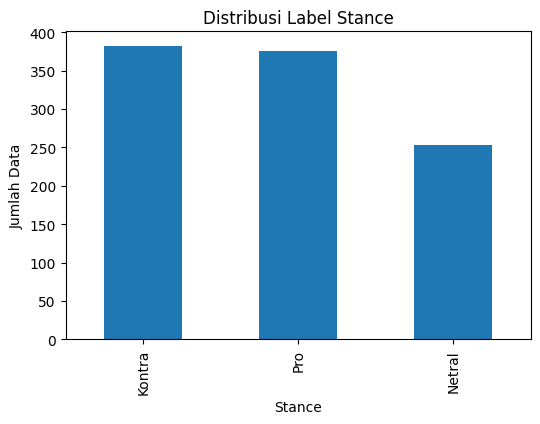

In [ ]:
stance_counts = df['label'].value_counts()

print(stance_counts)

plt.figure(figsize=(6,4))
stance_counts.plot(kind='bar')
plt.title('Distribusi Label Stance')
plt.xlabel('Stance')
plt.ylabel('Jumlah Data')
plt.show()

##**pie chart distribusi**

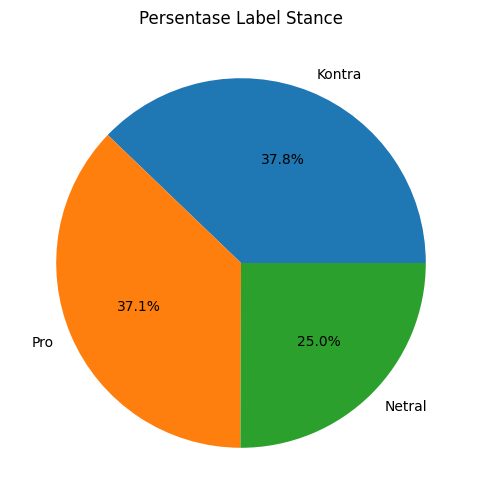

In [ ]:
plt.figure(figsize=(6,6))
df['label'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%'
)
plt.ylabel('')
plt.title('Persentase Label Stance')
plt.show()

##**distribusi panjang komentar**

In [ ]:
df['word_count'] = df['text'].astype(str).apply(lambda x: len(x.split()))

df['word_count'].describe()

,word_count
count,1010.000000
mean,12.304950
std,9.319145
min,1.000000
25%,6.000000
50%,10.000000
75%,16.000000
max,102.000000


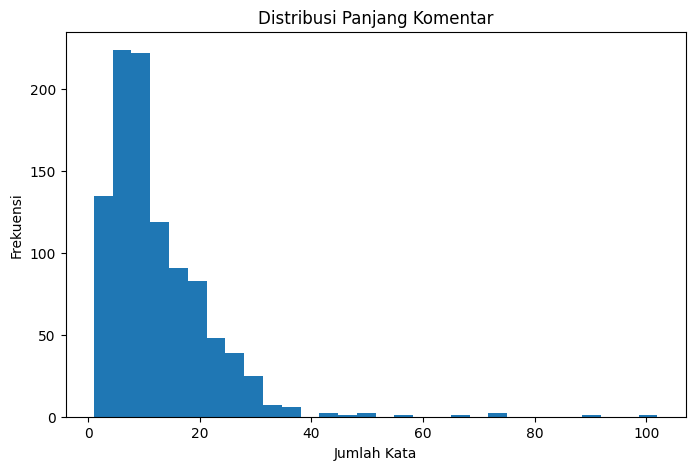

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(df['word_count'], bins=30)
plt.title('Distribusi Panjang Komentar')
plt.xlabel('Jumlah Kata')
plt.ylabel('Frekuensi')
plt.show()

##**wordcloud label pro**

NameError: name 'WordCloud' is not defined

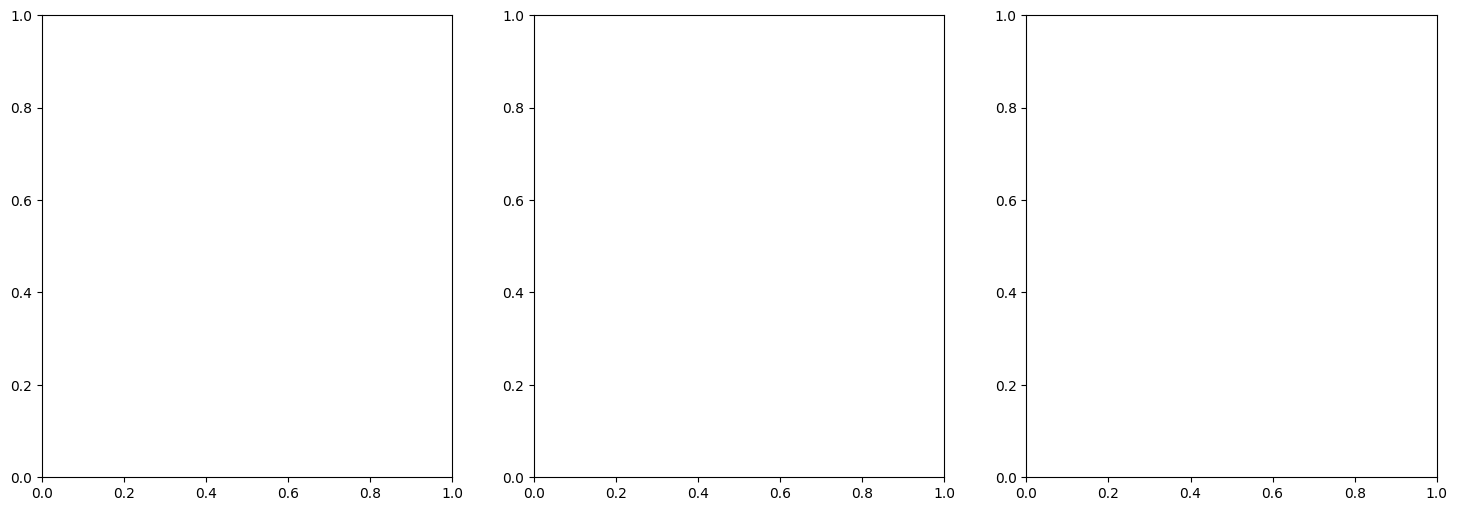

In [ ]:
texts = {
    'Pro': ' '.join(df[df['label']=='Pro']['text'].astype(str)),
    'Kontra': ' '.join(df[df['label']=='Kontra']['text'].astype(str)),
    'Netral': ' '.join(df[df['label']=='Netral']['text'].astype(str))
}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (label, text) in zip(axes, texts.items()):
    wc = WordCloud(
        width=800,
        height=400,
        background_color='white'
    ).generate(text)

    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(label, fontsize=14)
    ax.axis('off')

plt.tight_layout()
plt.show()

##**top 20 kata per stance**

In [ ]:
# Fungsi mengambil top words
def get_top_words(text_series, n=20):
    words = ' '.join(text_series.astype(str)).split()
    return pd.DataFrame(
        Counter(words).most_common(n),
        columns=['kata', 'frekuensi']
    )

# Ambil top words masing-masing stance
pro_df = get_top_words(
    df[df['label'] == 'Pro']['text']
)

kontra_df = get_top_words(
    df[df['label'] == 'Kontra']['text']
)

netral_df = get_top_words(
    df[df['label'] == 'Netral']['text']
)

# Plot
fig, axes = plt.subplots(1, 3, figsize=(20, 8))

# Pro
axes[0].barh(
    pro_df['kata'],
    pro_df['frekuensi']
)
axes[0].set_title('Pro')
axes[0].invert_yaxis()

# Kontra
axes[1].barh(
    kontra_df['kata'],
    kontra_df['frekuensi']
)
axes[1].set_title('Kontra')
axes[1].invert_yaxis()

# Netral
axes[2].barh(
    netral_df['kata'],
    netral_df['frekuensi']
)
axes[2].set_title('Netral')
axes[2].invert_yaxis()

plt.suptitle(
    'Top 20 Kata Berdasarkan Stance',
    fontsize=16
)

plt.tight_layout()
plt.show()

##**top 10 bigram**

In [ ]:
# Fungsi mengambil top bigram
def get_top_bigrams(text_series, n=10):

    words = ' '.join(
        text_series.astype(str)
    ).split()

    bigram_freq = Counter(
        bigrams(words)
    ).most_common(n)

    bigram_df = pd.DataFrame(
        bigram_freq,
        columns=['bigram', 'frekuensi']
    )

    bigram_df['bigram'] = bigram_df['bigram'].apply(
        lambda x: ' '.join(x)
    )

    return bigram_df

# Ambil bigram tiap stance
pro_bigram = get_top_bigrams(
    df[df['label'] == 'Pro']['text']
)

kontra_bigram = get_top_bigrams(
    df[df['label'] == 'Kontra']['text']
)

netral_bigram = get_top_bigrams(
    df[df['label'] == 'Netral']['text']
)

# Plot
fig, axes = plt.subplots(1, 3, figsize=(22, 8))

# PRO
axes[0].barh(
    pro_bigram['bigram'],
    pro_bigram['frekuensi']
)
axes[0].set_title('Pro')
axes[0].invert_yaxis()

for i, v in enumerate(pro_bigram['frekuensi']):
    axes[0].text(v, i, str(v), va='center')

# KONTRA
axes[1].barh(
    kontra_bigram['bigram'],
    kontra_bigram['frekuensi']
)
axes[1].set_title('Kontra')
axes[1].invert_yaxis()

for i, v in enumerate(kontra_bigram['frekuensi']):
    axes[1].text(v, i, str(v), va='center')

# NETRAL
axes[2].barh(
    netral_bigram['bigram'],
    netral_bigram['frekuensi']
)
axes[2].set_title('Netral')
axes[2].invert_yaxis()

for i, v in enumerate(netral_bigram['frekuensi']):
    axes[2].text(v, i, str(v), va='center')

plt.suptitle(
    'Top 10 Bigram Berdasarkan Stance',
    fontsize=16
)

plt.tight_layout()
plt.show()

##**jumlah kata sebelum dan sesudah preprocessing**

In [ ]:
raw_df = pd.read_csv('/content/drive/MyDrive/SKRIPSI/data_opini.csv')
raw_words = raw_df['text'].astype(str).str.split().str.len().sum()

clean_words = df['text'].astype(str).str.split().str.len().sum()

print("Sebelum:", raw_words)
print("Sesudah:", clean_words)

In [ ]:
print("Jumlah Data :", len(df))

print("Jumlah Pro :",
      len(df[df['stance']==0]))

print("Jumlah Kontra :",
      len(df[df['stance']==2]))

print("Jumlah Netral :",
      len(df[df['stance']==3]))

print("Rata-rata kata :",
      round(df['word_count'].mean(),2))

print("Komentar terpanjang :",
      df['word_count'].max())

print("Komentar terpendek :",
      df['word_count'].min())

#**BASELINE**

In [ ]:
baseline_pipeline = Pipeline([
    (
        'tfidf',
        TfidfVectorizer(
            ngram_range=(1, 2),
            max_features=5000,
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )
    ),

    (
        'selector',
        SelectKBest(
            score_func=chi2,
            k=2000
        )
    ),

    (
        'svm',
        LinearSVC(
            C=1,
            class_weight='balanced',
            random_state=42
        )
    )
])

print("Baseline pipeline berhasil dibuat.")

Baseline pipeline berhasil dibuat.


In [ ]:
baseline_results = []

for fold, (train_idx, val_idx) in enumerate(
    skf.split(X, y),
    start=1
):

    X_train = X.iloc[train_idx]
    X_val = X.iloc[val_idx]

    y_train = y.iloc[train_idx]
    y_val = y.iloc[val_idx]

    # Training
    baseline_pipeline.fit(X_train, y_train)

    # Prediksi
    y_pred = baseline_pipeline.predict(X_val)

    # Metrics
    accuracy = accuracy_score(y_val, y_pred)
    precision = precision_score(
        y_val,
        y_pred,
        average='weighted',
        zero_division=0
    )
    recall = recall_score(
        y_val,
        y_pred,
        average='weighted',
        zero_division=0
    )
    f1 = f1_score(
        y_val,
        y_pred,
        average='weighted',
        zero_division=0
    )

    baseline_results.append({
        'Fold': fold,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

    print(f"\nFold {fold}")
    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-Score : {f1:.4f}")

/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=2000 is greater than n_features=1496. All the features will be returned.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=2000 is greater than n_features=1547. All the features will be returned.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=2000 is greater than n_features=1539. All the features will be returned.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=2000 is greater than n_features=1503. All the features will be returned.
  warnings.warn(



Fold 1
Accuracy : 0.6535
Precision: 0.6422
Recall   : 0.6535
F1-Score : 0.6466

Fold 2
Accuracy : 0.6733
Precision: 0.6653
Recall   : 0.6733
F1-Score : 0.6676

Fold 3
Accuracy : 0.6535
Precision: 0.6484
Recall   : 0.6535
F1-Score : 0.6503

Fold 4
Accuracy : 0.6733
Precision: 0.6671
Recall   : 0.6733
F1-Score : 0.6685

Fold 5
Accuracy : 0.6832
Precision: 0.6846
Recall   : 0.6832
F1-Score : 0.6836


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=2000 is greater than n_features=1543. All the features will be returned.
  warnings.warn(


In [ ]:
baseline_results_df = pd.DataFrame(baseline_results)

print("HASIL BASELINE SVM")
display(baseline_results_df)

HASIL BASELINE SVM


,Fold,Accuracy,Precision,Recall,F1-Score
0,1,0.653465,0.642235,0.653465,0.646639
1,2,0.673267,0.665277,0.673267,0.667649
2,3,0.653465,0.648446,0.653465,0.650268
3,4,0.673267,0.667136,0.673267,0.668455
4,5,0.683168,0.684608,0.683168,0.683601


In [ ]:
baseline_summary = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score'
    ],

    'Mean': [
        baseline_results_df['Accuracy'].mean(),
        baseline_results_df['Precision'].mean(),
        baseline_results_df['Recall'].mean(),
        baseline_results_df['F1-Score'].mean()
    ],

    'Std': [
        baseline_results_df['Accuracy'].std(),
        baseline_results_df['Precision'].std(),
        baseline_results_df['Recall'].std(),
        baseline_results_df['F1-Score'].std()
    ]
})

print("RINGKASAN BASELINE SVM")
display(baseline_summary)

RINGKASAN BASELINE SVM


,Metric,Mean,Std
0,Accuracy,0.667327,0.013284
1,Precision,0.661540,0.016745
2,Recall,0.667327,0.013284
3,F1-Score,0.663322,0.015042


#**OPTIMASI HYPERPARAMETERTUNING**

In [ ]:
tuning_pipeline = Pipeline([
    (
        'tfidf',
        TfidfVectorizer()
    ),

    (
        'selector',
        SelectKBest(
            score_func=chi2
        )
    ),

    (
        'svm',
        LinearSVC(
            class_weight='balanced',
            random_state=42
        )
    )
])

print("Pipeline tuning berhasil dibuat.")

Pipeline tuning berhasil dibuat.


In [ ]:
param_grid = {

    # TF-IDF
    'tfidf__ngram_range': [
        (1, 1),
        (1, 2)
    ],

    'tfidf__max_features': [
        3000,
        5000,
        10000
    ],

    'tfidf__min_df': [
        1,
        2,
        3
    ],

    'tfidf__max_df': [
        0.90,
        0.95,
        1.0
    ],

    'tfidf__sublinear_tf': [
        True
    ],

    # Chi-Square
    'selector__k': [
        1000,
        2000,
        3000,
        4000
    ],

    # LinearSVC
    'svm__C': [
        0.1,
        1,
        10
    ]
}

print("Jumlah kombinasi hyperparameter:")

jumlah_kombinasi = (
    len(param_grid['tfidf__ngram_range'])
    * len(param_grid['tfidf__max_features'])
    * len(param_grid['tfidf__min_df'])
    * len(param_grid['tfidf__max_df'])
    * len(param_grid['tfidf__sublinear_tf'])
    * len(param_grid['selector__k'])
    * len(param_grid['svm__C'])
)

print(jumlah_kombinasi)
print("Total training dengan 5-fold:", jumlah_kombinasi * 5)

Jumlah kombinasi hyperparameter:
648
Total training dengan 5-fold: 3240


In [ ]:
feature_param_grid = {

    'tfidf__ngram_range': [
        (1, 1),
        (1, 2)
    ],

    'tfidf__max_features': [
        3000,
        5000,
        10000
    ],

    'tfidf__min_df': [
        1,
        2,
        3
    ],

    'tfidf__max_df': [
        0.90,
        0.95,
        1.0
    ],

    'tfidf__sublinear_tf': [
        True
    ],

    'selector__k': [
        1000,
        2000,
        3000,
        4000
    ],

    'svm__C': [
        1
    ]
}

In [ ]:
grid_feature = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=feature_param_grid,
    scoring='f1_weighted',
    cv=skf,
    n_jobs=-1,
    verbose=2,
    return_train_score=True
)

grid_feature.fit(X, y)

print("\nGrid Search Tahap 1 selesai.")

Fitting 5 folds for each of 216 candidates, totalling 1080 fits

Grid Search Tahap 1 selesai.


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=3000 is greater than n_features=2860. All the features will be returned.
  warnings.warn(


In [ ]:
print("===================================")
print("PARAMETER TERBAIK TAHAP 1")
print("===================================")

for parameter, value in grid_feature.best_params_.items():
    print(f"{parameter}: {value}")

print("\nBest Weighted F1-Score:")
print(f"{grid_feature.best_score_:.4f}")

PARAMETER TERBAIK TAHAP 1
selector__k: 3000
svm__C: 1
tfidf__max_df: 0.9
tfidf__max_features: 3000
tfidf__min_df: 1
tfidf__ngram_range: (1, 1)
tfidf__sublinear_tf: True

Best Weighted F1-Score:
0.6871


In [ ]:
best_feature_params = grid_feature.best_params_

best_ngram = best_feature_params['tfidf__ngram_range']
best_max_features = best_feature_params['tfidf__max_features']
best_min_df = best_feature_params['tfidf__min_df']
best_max_df = best_feature_params['tfidf__max_df']
best_sublinear = best_feature_params['tfidf__sublinear_tf']
best_k = best_feature_params['selector__k']

print("Parameter feature extraction terbaik:")
print("ngram_range   :", best_ngram)
print("max_features  :", best_max_features)
print("min_df        :", best_min_df)
print("max_df        :", best_max_df)
print("sublinear_tf  :", best_sublinear)
print("k             :", best_k)

Parameter feature extraction terbaik:
ngram_range   : (1, 1)
max_features  : 3000
min_df        : 1
max_df        : 0.9
sublinear_tf  : True
k             : 3000


# **OPTIMASI C**

In [ ]:
svm_tuning_pipeline = Pipeline([

    (
        'tfidf',
        TfidfVectorizer(
            ngram_range=best_ngram,
            max_features=best_max_features,
            min_df=best_min_df,
            max_df=best_max_df,
            sublinear_tf=best_sublinear
        )
    ),

    (
        'selector',
        SelectKBest(
            score_func=chi2,
            k=best_k
        )
    ),

    (
        'svm',
        LinearSVC(
            class_weight='balanced',
            random_state=42
        )
    )
])

print("Pipeline SVM untuk optimasi C berhasil dibuat.")

Pipeline SVM untuk optimasi C berhasil dibuat.


In [ ]:
C_param_grid = {
    'svm__C': [
        0.001,
        0.01,
        0.1,
        1,
        10,
        100
    ]
}

print("Nilai C yang akan diuji:")
print(C_param_grid['svm__C'])

Nilai C yang akan diuji:
[0.001, 0.01, 0.1, 1, 10, 100]


In [ ]:
grid_C = GridSearchCV(
    estimator=svm_tuning_pipeline,
    param_grid=C_param_grid,
    scoring='f1_weighted',
    cv=skf,
    n_jobs=-1,
    verbose=2,
    return_train_score=True
)

grid_C.fit(X, y)

print("\nGrid Search C selesai.")

Fitting 5 folds for each of 6 candidates, totalling 30 fits

Grid Search C selesai.


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=3000 is greater than n_features=2860. All the features will be returned.
  warnings.warn(


In [ ]:
print("===================================")
print("PARAMETER SVM TERBAIK")
print("===================================")

for parameter, value in grid_C.best_params_.items():
    print(f"{parameter}: {value}")

print("\nBest Weighted F1-Score:")
print(f"{grid_C.best_score_:.4f}")

PARAMETER SVM TERBAIK
svm__C: 1

Best Weighted F1-Score:
0.6871


In [ ]:
C_results = pd.DataFrame(grid_C.cv_results_)

C_results = C_results[
    [
        'param_svm__C',
        'mean_train_score',
        'mean_test_score',
        'std_test_score',
        'rank_test_score'
    ]
].sort_values(
    'param_svm__C'
)

display(C_results)

,param_svm__C,mean_train_score,mean_test_score,std_test_score,rank_test_score
0,0.001,0.581899,0.538358,0.019089,6
1,0.010,0.673680,0.566585,0.011603,5
2,0.100,0.931078,0.675126,0.022631,2
3,1.000,0.997773,0.687125,0.016109,1
4,10.000,0.999010,0.663773,0.007378,4
5,100.000,0.999010,0.666326,0.006562,3


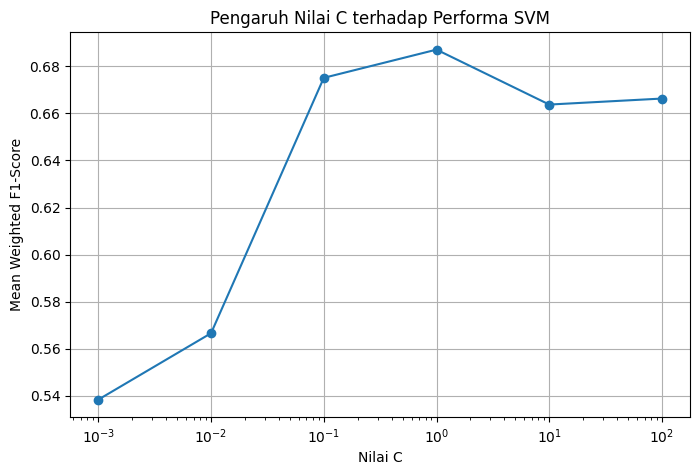

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    C_results['param_svm__C'].astype(float),
    C_results['mean_test_score'],
    marker='o'
)

plt.xscale('log')

plt.xlabel('Nilai C')
plt.ylabel('Mean Weighted F1-Score')
plt.title('Pengaruh Nilai C terhadap Performa SVM')

plt.grid(True)
plt.show()

#**MODEL SVM TEROPTIMASI**

In [ ]:
best_svm_model = grid_C.best_estimator_

print("Model SVM terbaik berhasil diperoleh.")

Model SVM terbaik berhasil diperoleh.


In [ ]:
final_params = best_svm_model.get_params()

print("===================================")
print("KONFIGURASI AKHIR SVM")
print("===================================")

print("TF-IDF")
print("ngram_range  :", final_params['tfidf__ngram_range'])
print("max_features :", final_params['tfidf__max_features'])
print("min_df       :", final_params['tfidf__min_df'])
print("max_df       :", final_params['tfidf__max_df'])
print("sublinear_tf :", final_params['tfidf__sublinear_tf'])

print("\nSelectKBest")
print("k            :", final_params['selector__k'])

print("\nLinearSVC")
print("C            :", final_params['svm__C'])
print("class_weight :", final_params['svm__class_weight'])

KONFIGURASI AKHIR SVM
TF-IDF
ngram_range  : (1, 1)
max_features : 3000
min_df       : 1
max_df       : 0.9
sublinear_tf : True

SelectKBest
k            : 3000

LinearSVC
C            : 1
class_weight : balanced


In [ ]:
optimized_results = []

for fold, (train_idx, val_idx) in enumerate(
    skf.split(X, y),
    start=1
):

    X_train = X.iloc[train_idx]
    X_val = X.iloc[val_idx]

    y_train = y.iloc[train_idx]
    y_val = y.iloc[val_idx]

    # Training model terbaik
    best_svm_model.fit(X_train, y_train)

    # Prediksi validation
    y_pred = best_svm_model.predict(X_val)

    # Metrics
    accuracy = accuracy_score(y_val, y_pred)

    precision = precision_score(
        y_val,
        y_pred,
        average='weighted',
        zero_division=0
    )

    recall = recall_score(
        y_val,
        y_pred,
        average='weighted',
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        y_pred,
        average='weighted',
        zero_division=0
    )

    optimized_results.append({
        'Fold': fold,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

    print(f"\nFold {fold}")
    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-Score : {f1:.4f}")


Fold 1
Accuracy : 0.6782
Precision: 0.6730
Recall   : 0.6782
F1-Score : 0.6741

Fold 2
Accuracy : 0.7030
Precision: 0.7005
Recall   : 0.7030
F1-Score : 0.6968

Fold 3
Accuracy : 0.6931
Precision: 0.6919
Recall   : 0.6931
F1-Score : 0.6923

Fold 4
Accuracy : 0.6683
Precision: 0.6611
Recall   : 0.6683
F1-Score : 0.6638

Fold 5
Accuracy : 0.7079
Precision: 0.7103
Recall   : 0.7079
F1-Score : 0.7086


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=3000 is greater than n_features=2469. All the features will be returned.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=3000 is greater than n_features=2494. All the features will be returned.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=3000 is greater than n_features=2499. All the features will be returned.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=3000 is greater than n_features=2447. All the features will be returned.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=3000 is greater than n_features=2512. All the features will be returned.
  warnings.w

In [ ]:
optimized_results_df = pd.DataFrame(
    optimized_results
)

print("HASIL SVM SETELAH OPTIMASI")
display(optimized_results_df)

HASIL SVM SETELAH OPTIMASI


,Fold,Accuracy,Precision,Recall,F1-Score
0,1,0.678218,0.673017,0.678218,0.674113
1,2,0.702970,0.700455,0.702970,0.696750
2,3,0.693069,0.691930,0.693069,0.692334
3,4,0.668317,0.661086,0.668317,0.663777
4,5,0.707921,0.710323,0.707921,0.708650


In [ ]:
optimized_summary = pd.DataFrame({

    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score'
    ],

    'Mean': [
        optimized_results_df['Accuracy'].mean(),
        optimized_results_df['Precision'].mean(),
        optimized_results_df['Recall'].mean(),
        optimized_results_df['F1-Score'].mean()
    ],

    'Std': [
        optimized_results_df['Accuracy'].std(),
        optimized_results_df['Precision'].std(),
        optimized_results_df['Recall'].std(),
        optimized_results_df['F1-Score'].std()
    ]
})

print("===================================")
print("HASIL AKHIR SVM TEROPTIMASI")
print("===================================")

display(optimized_summary)

HASIL AKHIR SVM TEROPTIMASI


,Metric,Mean,Std
0,Accuracy,0.690099,0.016641
1,Precision,0.687362,0.020098
2,Recall,0.690099,0.016641
3,F1-Score,0.687125,0.018011


In [ ]:
comparison_df = pd.DataFrame({

    'Model': [
        'SVM Baseline',
        'SVM Optimasi'
    ],

    'Accuracy': [
        baseline_results_df['Accuracy'].mean(),
        optimized_results_df['Accuracy'].mean()
    ],

    'Precision': [
        baseline_results_df['Precision'].mean(),
        optimized_results_df['Precision'].mean()
    ],

    'Recall': [
        baseline_results_df['Recall'].mean(),
        optimized_results_df['Recall'].mean()
    ],

    'F1-Score': [
        baseline_results_df['F1-Score'].mean(),
        optimized_results_df['F1-Score'].mean()
    ]
})

display(comparison_df)

,Model,Accuracy,Precision,Recall,F1-Score
0,SVM Baseline,0.667327,0.661540,0.667327,0.663322
1,SVM Optimasi,0.690099,0.687362,0.690099,0.687125


In [ ]:
improvement = pd.DataFrame({

    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score'
    ],

    'Baseline': [
        baseline_results_df['Accuracy'].mean(),
        baseline_results_df['Precision'].mean(),
        baseline_results_df['Recall'].mean(),
        baseline_results_df['F1-Score'].mean()
    ],

    'Optimasi': [
        optimized_results_df['Accuracy'].mean(),
        optimized_results_df['Precision'].mean(),
        optimized_results_df['Recall'].mean(),
        optimized_results_df['F1-Score'].mean()
    ]
})

improvement['Improvement'] = (
    improvement['Optimasi']
    - improvement['Baseline']
)

improvement['Improvement (%)'] = (
    improvement['Improvement'] * 100
)

display(improvement)

,Metric,Baseline,Optimasi,Improvement,Improvement (%)
0,Accuracy,0.667327,0.690099,0.022772,2.277228
1,Precision,0.661540,0.687362,0.025822,2.582185
2,Recall,0.667327,0.690099,0.022772,2.277228
3,F1-Score,0.663322,0.687125,0.023802,2.380237


# **CLASIFICATION REPORT**

In [ ]:
y_true_all = []
y_pred_all = []

for fold, (train_idx, val_idx) in enumerate(
    skf.split(X, y),
    start=1
):

    X_train = X.iloc[train_idx]
    X_val = X.iloc[val_idx]

    y_train = y.iloc[train_idx]
    y_val = y.iloc[val_idx]

    best_svm_model.fit(
        X_train,
        y_train
    )

    y_pred = best_svm_model.predict(
        X_val
    )

    y_true_all.extend(
        y_val.tolist()
    )

    y_pred_all.extend(
        y_pred.tolist()
    )

print("Jumlah data aktual   :", len(y_true_all))
print("Jumlah data prediksi :", len(y_pred_all))

/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=3000 is greater than n_features=2469. All the features will be returned.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=3000 is greater than n_features=2494. All the features will be returned.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=3000 is greater than n_features=2499. All the features will be returned.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=3000 is greater than n_features=2447. All the features will be returned.
  warnings.warn(


Jumlah data aktual   : 1010
Jumlah data prediksi : 1010


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=3000 is greater than n_features=2512. All the features will be returned.
  warnings.warn(


In [ ]:
print("===================================")
print("CLASSIFICATION REPORT")
print("SVM SETELAH OPTIMASI")
print("===================================")

print(
    classification_report(
        y_true_all,
        y_pred_all,
        target_names=[
            'Pro',
            'Kontra',
            'Netral'
        ],
        digits=4,
        zero_division=0
    )
)

CLASSIFICATION REPORT
SVM SETELAH OPTIMASI
              precision    recall  f1-score   support

         Pro     0.7647    0.7973    0.7807       375
      Kontra     0.7069    0.7199    0.7134       382
      Netral     0.5348    0.4862    0.5093       253

    accuracy                         0.6901      1010
   macro avg     0.6688    0.6678    0.6678      1010
weighted avg     0.6853    0.6901    0.6872      1010



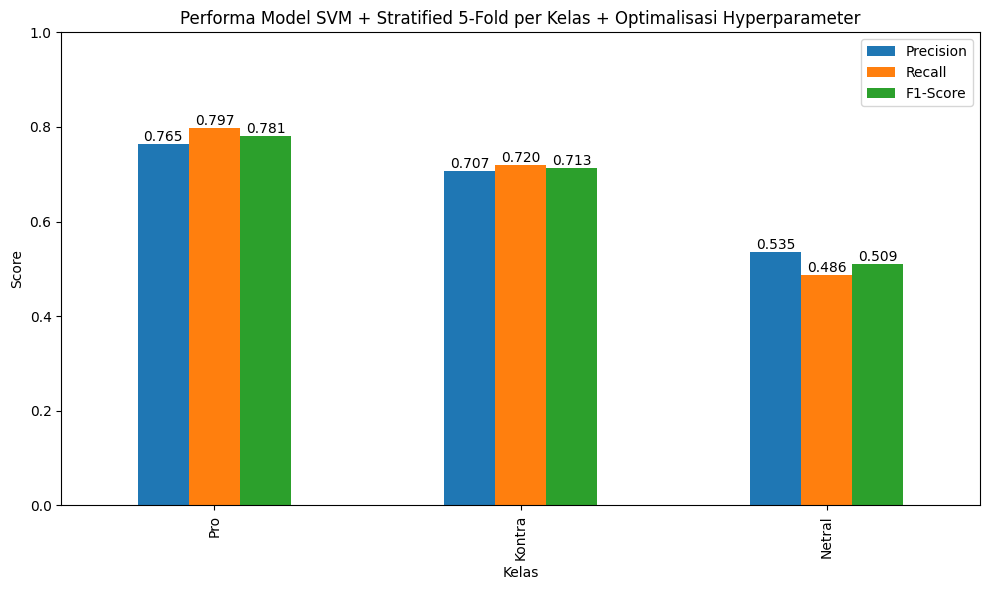

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Data dari classification report
df_metrics = pd.DataFrame({
    'Precision': [0.7647, 0.7069, 0.5348],
    'Recall':    [0.7973, 0.7199, 0.4862],
    'F1-Score':  [0.7807, 0.7134, 0.5093]
}, index=['Pro', 'Kontra', 'Netral'])

# Plot
ax = df_metrics.plot(
    kind='bar',
    figsize=(10,6)
)

plt.title('Performa Model SVM + Stratified 5-Fold per Kelas + Optimalisasi Hyperparameter')
plt.ylabel('Score')
plt.xlabel('Kelas')
plt.ylim(0, 1)
plt.legend(loc='upper right')

# Menampilkan nilai di atas batang
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f')

plt.tight_layout()
plt.show()

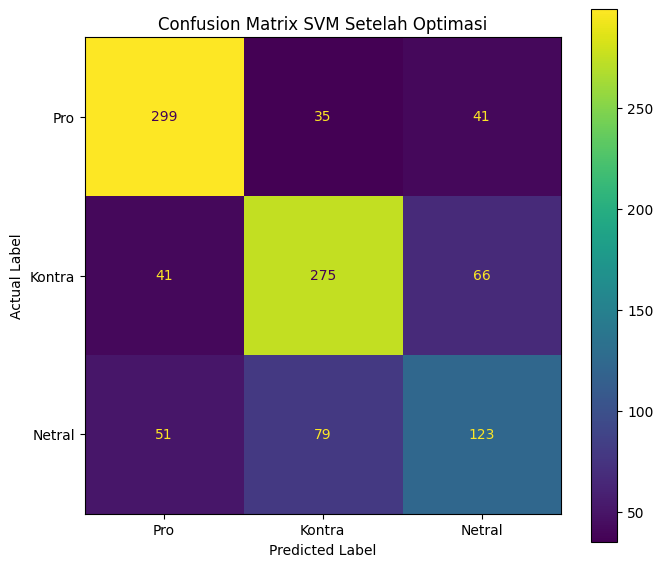

In [ ]:
cm = confusion_matrix(
    y_true_all,
    y_pred_all
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        'Pro',
        'Kontra',
        'Netral'
    ]
)

fig, ax = plt.subplots(
    figsize=(7, 6)
)

disp.plot(
    ax=ax,
    cmap='viridis',
    values_format='d'
)

ax.set_title(
    'Confusion Matrix SVM Setelah Optimasi'
)

ax.set_xlabel(
    'Predicted Label'
)

ax.set_ylabel(
    'Actual Label'
)

plt.tight_layout()
plt.show()

#**TES KALIMAT**

In [ ]:
contoh_kalimat = [
    "Semoga aja program ini bakal sukses wujudin program kethanan pangan"
]

# Prediksi
prediksi = best_svm_model.predict(contoh_kalimat)[0]

# Decision score
scores = best_svm_model.decision_function(contoh_kalimat)[0]

# Softmax → persentase relatif
exp_scores = np.exp(scores - np.max(scores))
persentase = exp_scores / exp_scores.sum() * 100

# Mapping label
label_map = {
    0: "Pro",
    2: "Kontra",
    3: "Netral"
}

print("=" * 50)
print("HASIL PREDIKSI SVM")
print("=" * 50)

print("Kalimat :", contoh_kalimat[0])
print("Prediksi:", label_map[prediksi])

print("\nPersentase:")
for cls, persen in zip(best_svm_model.classes_, persentase):
    print(f"{label_map[cls]:8}: {persen:.2f}%")

HASIL PREDIKSI SVM
Kalimat : Semoga aja program ini bakal sukses wujudin program kethanan pangan
Prediksi: Pro

Persentase:
Pro     : 77.51%
Kontra  : 15.72%
Netral  : 6.77%


In [ ]:
contoh_kalimat = [
    "Agak pesimis sih tapi kita percayakan aja pada pemerintah"
]

# Prediksi
prediksi = best_svm_model.predict(contoh_kalimat)[0]

# Decision score
scores = best_svm_model.decision_function(contoh_kalimat)[0]

# Softmax → persentase relatif
exp_scores = np.exp(scores - np.max(scores))
persentase = exp_scores / exp_scores.sum() * 100

# Mapping label
label_map = {
    0: "Pro",
    2: "Kontra",
    3: "Netral"
}

print("=" * 50)
print("HASIL PREDIKSI SVM")
print("=" * 50)

print("Kalimat :", contoh_kalimat[0])
print("Prediksi:", label_map[prediksi])

print("\nPersentase:")
for cls, persen in zip(best_svm_model.classes_, persentase):
    print(f"{label_map[cls]:8}: {persen:.2f}%")

HASIL PREDIKSI SVM
Kalimat : Agak pesimis sih tapi kita percayakan aja pada pemerintah
Prediksi: Netral

Persentase:
Pro     : 30.36%
Kontra  : 18.32%
Netral  : 51.31%


In [ ]:
contoh_kalimat = [
    "Program ga jelas, buang-buang anggaran saja"
]

# Prediksi
prediksi = best_svm_model.predict(contoh_kalimat)[0]

# Decision score
scores = best_svm_model.decision_function(contoh_kalimat)[0]

# Softmax → persentase relatif
exp_scores = np.exp(scores - np.max(scores))
persentase = exp_scores / exp_scores.sum() * 100

# Mapping label
label_map = {
    0: "Pro",
    2: "Kontra",
    3: "Netral"
}

print("=" * 50)
print("HASIL PREDIKSI SVM")
print("=" * 50)

print("Kalimat :", contoh_kalimat[0])
print("Prediksi:", label_map[prediksi])

print("\nPersentase:")
for cls, persen in zip(best_svm_model.classes_, persentase):
    print(f"{label_map[cls]:8}: {persen:.2f}%")

HASIL PREDIKSI SVM
Kalimat : Program ga jelas, buang-buang anggaran saja
Prediksi: Kontra

Persentase:
Pro     : 36.22%
Kontra  : 50.21%
Netral  : 13.56%


In [ ]:
contoh_kalimat = [
    "yakin banget gue ini bakal menjadi program yang gagal total"
]

# Prediksi
prediksi = best_svm_model.predict(contoh_kalimat)[0]

# Decision score
scores = best_svm_model.decision_function(contoh_kalimat)[0]

# Softmax → persentase relatif
exp_scores = np.exp(scores - np.max(scores))
persentase = exp_scores / exp_scores.sum() * 100

# Mapping label
label_map = {
    0: "Pro",
    2: "Kontra",
    3: "Netral"
}

print("=" * 50)
print("HASIL PREDIKSI SVM")
print("=" * 50)

print("Kalimat :", contoh_kalimat[0])
print("Prediksi:", label_map[prediksi])

print("\nPersentase:")
for cls, persen in zip(best_svm_model.classes_, persentase):
    print(f"{label_map[cls]:8}: {persen:.2f}%")

HASIL PREDIKSI SVM
Kalimat : yakin banget gue ini bakal menjadi program yang gagal total
Prediksi: Kontra

Persentase:
Pro     : 13.30%
Kontra  : 77.89%
Netral  : 8.80%


In [ ]:
contoh_kalimat = [
    "no komen, lihat aja ke depannya bakal gmna"
]

# Prediksi
prediksi = best_svm_model.predict(contoh_kalimat)[0]

# Decision score
scores = best_svm_model.decision_function(contoh_kalimat)[0]

# Softmax → persentase relatif
exp_scores = np.exp(scores - np.max(scores))
persentase = exp_scores / exp_scores.sum() * 100

# Mapping label
label_map = {
    0: "Pro",
    2: "Kontra",
    3: "Netral"
}

print("=" * 50)
print("HASIL PREDIKSI SVM")
print("=" * 50)

print("Kalimat :", contoh_kalimat[0])
print("Prediksi:", label_map[prediksi])

print("\nPersentase:")
for cls, persen in zip(best_svm_model.classes_, persentase):
    print(f"{label_map[cls]:8}: {persen:.2f}%")

HASIL PREDIKSI SVM
Kalimat : no komen, lihat aja ke depannya bakal gmna
Prediksi: Netral

Persentase:
Pro     : 32.35%
Kontra  : 31.81%
Netral  : 35.84%


In [ ]:
contoh_kalimat = [
    "saya nyimak aja bro, ga tau apa-apa soal program ini"
]

# Prediksi
prediksi = best_svm_model.predict(contoh_kalimat)[0]

# Decision score
scores = best_svm_model.decision_function(contoh_kalimat)[0]

# Softmax → persentase relatif
exp_scores = np.exp(scores - np.max(scores))
persentase = exp_scores / exp_scores.sum() * 100

# Mapping label
label_map = {
    0: "Pro",
    2: "Kontra",
    3: "Netral"
}

print("=" * 50)
print("HASIL PREDIKSI SVM")
print("=" * 50)

print("Kalimat :", contoh_kalimat[0])
print("Prediksi:", label_map[prediksi])

print("\nPersentase:")
for cls, persen in zip(best_svm_model.classes_, persentase):
    print(f"{label_map[cls]:8}: {persen:.2f}%")

HASIL PREDIKSI SVM
Kalimat : saya nyimak aja bro, ga tau apa-apa soal program ini
Prediksi: Pro

Persentase:
Pro     : 38.15%
Kontra  : 32.76%
Netral  : 29.09%
